In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 66.5 MB/s eta 0:00:00


In [2]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np


In [3]:
data =[
    "AI is transforming healthcare",
    "Natural language processing is fascinating",
    "self-driving cars rely on sensors",
    "chatbots imporve customer service",
    "computer vision powers facial recognition",
    "Robotics is recognitionizing manufacturing"
]

In [5]:
# tagging document

tagged_data = [TaggedDocument(words=d.split(), tags=[str(i)]) for i, d in enumerate(data)]

In [6]:
tagged_data

[TaggedDocument(words=['AI', 'is', 'transforming', 'healthcare'], tags=['0']),
 TaggedDocument(words=['Natural', 'language', 'processing', 'is', 'fascinating'], tags=['1']),
 TaggedDocument(words=['self-driving', 'cars', 'rely', 'on', 'sensors'], tags=['2']),
 TaggedDocument(words=['chatbots', 'imporve', 'customer', 'service'], tags=['3']),
 TaggedDocument(words=['computer', 'vision', 'powers', 'facial', 'recognition'], tags=['4']),
 TaggedDocument(words=['Robotics', 'is', 'recognitionizing', 'manufacturing'], tags=['5'])]

In [7]:
# training

model = Doc2Vec(vector_size=50, window=2, min_count=1, workers=4, epochs=40)
model.build_vocab(tagged_data)
model.train(tagged_data, total_examples=model.corpus_count, epochs=model.epochs)

In [8]:
vec = model.infer_vector(["deep", "learning"])
print(vec)

[ 8.9740427e-03 -3.9328714e-03  5.6232358e-03  2.6520228e-03
  8.6653233e-04  8.6087193e-03 -4.0609608e-03 -2.4702549e-03
  1.5983498e-03  4.4876100e-03  4.3787025e-03  3.4085917e-03
  7.6996135e-03 -6.1023938e-03 -1.6774470e-03  3.2555698e-03
 -7.4031381e-03  7.3501170e-03 -3.1198722e-03 -2.4938053e-03
  4.0052985e-03 -4.1879048e-03 -9.4638309e-03 -3.0596661e-03
 -4.5771347e-03 -1.0598421e-03 -7.0222695e-03 -2.8774858e-04
 -4.5972890e-03 -9.8407865e-05 -6.1875726e-03 -9.7839795e-03
  4.7812890e-03 -3.1041502e-05 -3.7270607e-04 -4.4740229e-03
 -2.1456392e-03 -3.2141637e-03 -3.9982121e-03 -6.5335892e-03
 -4.6832287e-03 -7.1623386e-04 -1.1029989e-03  4.8001860e-03
 -4.1103568e-03  5.5893827e-03 -2.2303342e-04 -3.3951092e-03
  6.7073110e-05  1.4439345e-04]


In [9]:
vectors = np.array([model.dv[str(i)] for i in range(len(tagged_data))])

In [10]:
vectors

array([[-1.11002317e-02, -1.22253876e-02, -1.99894719e-02,
         1.70571078e-02,  7.20006367e-03,  7.52347172e-04,
        -1.97482966e-02, -1.01700211e-02, -1.98031850e-02,
         4.33732476e-03,  5.83816040e-03,  9.82784666e-03,
        -8.43627937e-03, -6.68143248e-03, -5.98075241e-03,
        -1.77056324e-02,  4.30500088e-03,  1.86149441e-02,
        -1.93865672e-02, -7.11674709e-03, -7.91429263e-03,
         5.31601580e-03, -1.15722846e-02,  5.45044942e-03,
         1.16432160e-02, -1.62873901e-02, -1.70813836e-02,
        -2.03968622e-02,  9.77312494e-03, -1.85806789e-02,
         1.20454468e-02,  1.39105814e-02, -1.32984091e-02,
        -9.21498239e-03, -2.77628936e-03,  3.76431365e-03,
        -3.12945829e-03, -1.75014362e-02, -7.18838209e-03,
         3.45396018e-03, -4.28060954e-03, -1.42000141e-02,
         8.42534751e-03, -1.73976645e-02,  5.38314832e-03,
        -8.98157712e-03,  1.37246470e-03, -4.05228278e-03,
         1.12282867e-02, -1.63416285e-02],
       [-4.88

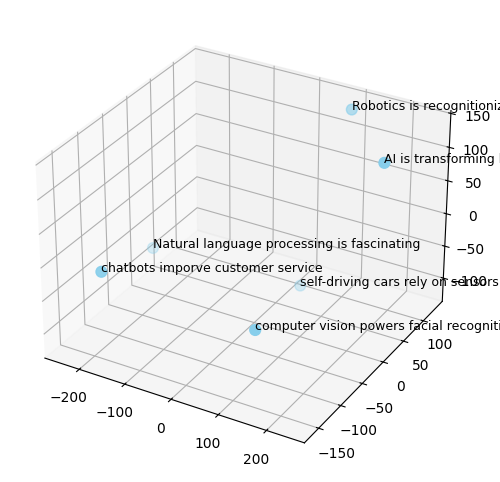

In [13]:
tsne = TSNE(n_components=3, random_state=42, perplexity=2)
reduced = tsne.fit_transform(vectors)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(reduced[:,0], reduced[:,1], reduced[:,2], c="skyblue", s = 60)

for i , txt in enumerate(data):
  ax.text(reduced[i, 0], reduced[i, 1], reduced[i, 2], txt, fontsize=9)

plt.show()

In [14]:
import gensim.downloader as api
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import numpy as np
import re

In [15]:
word_vectors = api.load('glove-wiki-gigaword-50')

[==================================================] 100.0% 66.0/66.0MB downloaded


In [16]:
data = [
    ("I loved the movie, it was fantastic!", "positive"),
    ("The movie was okay, not the best.", "neutral"),
    ("Terrible movie. Wouldn't recommend.", "negative"),
    ("Really enjoyed the characters and plot.", "positive"),
    ("It was boring and predictable.", "negative"),
    ("An average film, not too bad.", "neutral"),
    ("What a masterpiece, absolutely loved it!", "positive"),
    ("Poor acting and bad script. Waste of time.", "negative"),
    ("Nothing special, just another average film.", "neutral"),
    ("Incredible visuals and emotional story.", "positive"),
    ("Couldn't even finish it. So bad.", "negative"),
    ("Neither good nor bad. Just meh.", "neutral"),
    ("Brilliant performance by the lead actor!", "positive"),
    ("The plot was weak and unoriginal.", "negative"),
    ("Mediocre at best, not memorable.", "neutral"),
    ("Exceeded my expectations. A must-watch!", "positive"),
    ("The direction was sloppy and confusing.", "negative"),
    ("Some parts were good. Others not so much.", "neutral")
]

In [17]:
## Preprocess data

In [28]:
data = [
    ("I loved the movie, it was fantastic!", "positive"),
    ("The movie was okay, not the best.", "neutral"),
    ("Terrible movie. Wouldn't recommend.", "negative"),
    ("Really enjoyed the characters and plot.", "positive"),
    ("It was boring and predictable.", "negative"),
    ("An average film, not too bad.", "neutral"),
    ("What a masterpiece, absolutely loved it!", "positive"),
    ("Poor acting and bad script. Waste of time.", "negative"),
    ("Nothing special, just another average film.", "neutral"),
    ("Incredible visuals and emotional story.", "positive"),
    ("Couldn't even finish it. So bad.", "negative"),
    ("Neither good nor bad. Just meh.", "neutral"),
    ("Brilliant performance by the lead actor!", "positive"),
    ("The plot was weak and unoriginal.", "negative"),
    ("Mediocre at best, not memorable.", "neutral"),
    ("Exceeded my expectations. A must-watch!", "positive"),
    ("The direction was sloppy and confusing.", "negative"),
    ("Some parts were good. Others not so much.", "neutral")
]

def preprocess(text):
  text = text.lower()
  text = re.sub(r'[^\w\s]',"", text)
  return text.split()

def sentence_vector(sentence):
  words = preprocess(sentence)
  vectors = [word_vectors[word] for word in words if word in word_vectors]

  if not vectors:
    return np.zeros(word_vectors.vector_size)
  return np.mean(vectors, axis=0)

x=[sentence_vector(text) for text, _ in data]
y = [label for _, label in data]

clf = LogisticRegression(max_iter = 1000)
clf.fit(x, y)

new_review = "the plot was weak and unoriginal"
new_vec = sentence_vector(new_review)
predicted_label = clf.predict([new_vec])[0]
print(f"{new_review}:", predicted_label)

the plot was weak and unoriginal: negative
